# Cartes

Les cartes montrent où se trouvent les départements les plus touchés par l'obésité, et si on retrouve les mêmes zones pour la pauvreté, les fast-foods et l'accès aux médecins.

## 1. Chargement

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

contours = gpd.read_file("../data/raw/departements.geojson")
df = pd.read_csv("../data/processed/departements.csv", dtype={"dep": str, "region": str})

carte = contours.merge(df, left_on="code", right_on="dep")
carte = carte.to_crs(2154)
carte.shape

(96, 20)

On relie les contours des départements à la table par leur code. `to_crs(2154)` change la projection en Lambert-93, la projection officielle de la France : sans ça, la carte paraît étirée.

## 2. Obésité

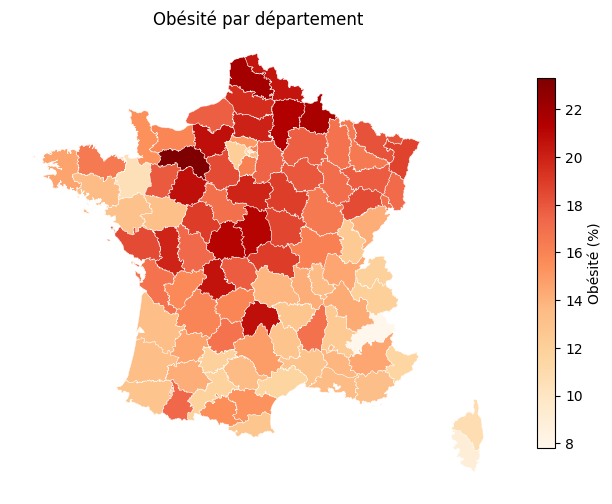

In [2]:
fig, ax = plt.subplots(figsize=(8, 8))
carte.plot(
    column="obesite",
    cmap="OrRd",
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    ax=ax,
    legend_kwds={"label": "Obésité (%)", "shrink": 0.6},
)
ax.set_axis_off()
ax.set_title("Obésité par département")
plt.savefig("../figures/carte_obesite.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :** les taux les plus élevés sont dans le nord (Hauts-de-France), en Normandie et dans un large centre du pays. Les taux les plus faibles sont dans le sud-est et les Alpes, en Corse, à Paris et en Ille-et-Vilaine. On voit un contraste entre le nord et le centre d'un côté, et le sud de l'autre. Les départements voisins ont des taux proches : la région compte beaucoup, ce que la régression a confirmé.